# PG vs TSLA Hedging Project — Continuous Time Finance

**Research Question 1 (vol risk premium):** Does implied vol persistently run above realized vol for
PG and TSLA, such that delta-hedging a sold ATM call is profitable on average — and does the premium
differ between TSLA (high-vol growth) and PG (defensive)?

**Research Question 2 (regime dependence):** Does hedging error behave differently across market
regimes (2022 rate-hike stress, 2023 calm, and the Jan-Apr 2025 AI/DeepSeek shock) — and is TSLA more
regime-sensitive than PG?

**Data:** this repository does not include the Bloomberg data. To rerun the analysis, export daily
Date, Price and Implied Vol (HIVG function, 30-day tenor, Classical model, 252 annualization) for PG
and TSLA from a Bloomberg Terminal for Jan 3, 2022 - Apr 30, 2025 and save them as
`PG_Options_Data_2022_2025.xlsx` and `Tesla_Options_Data_2022_2025.xlsx` in the same folder as this
notebook. Each file needs the columns `Date`, `Price` and `Implied Vol` (in percent).


## 1. Setup

In [1]:
!pip install -q numpy pandas scipy matplotlib
import numpy as np
import pandas as pd
from scipy.stats import norm, ttest_ind
import matplotlib.pyplot as plt

TRADING_DAYS_PER_YEAR = 252
MATURITY_TRADING_DAYS = 21  # ~30 calendar days
RISK_FREE_RATE = 0.02
DIVIDEND_YIELD = {"PG": 0.025, "TSLA": 0.0}

IV_SAMPLE_START = "2022-01-01"
IV_SAMPLE_END = "2025-04-30"

REGIME_WINDOWS = {
    "2022_rate_hike_stress": ("2022-01-01", "2022-12-31"),
    "2023_calm": ("2023-01-01", "2023-12-31"),
    "2025_ai_shock": ("2025-01-01", "2025-04-30"),
}
REGIME_ORDER = list(REGIME_WINDOWS.keys())
REGIME_LABEL = {
    "2022_rate_hike_stress": "2022\n(rate-hike stress)",
    "2023_calm": "2023\n(calm baseline)",
    "2025_ai_shock": "2025\n(AI shock, Jan-Apr)",
}

# Fixed colors, reused consistently across every figure
TICKER_COLOR = {"PG": "#2a78d6", "TSLA": "#008300"}
VOL_INPUT_COLOR = {"realized": "#2a78d6", "implied": "#eb6834"}

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "#888888", "axes.grid": True,
    "grid.color": "#e5e5e5", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 11,
})


## 2. Load data
Reads the two Bloomberg exports (Date, Price, Implied Vol %) from local Excel files and writes working CSVs. The data files are not included in this repository.

In [ ]:
import os

DATA_FILES = {
    "PG": "PG_Options_Data_2022_2025.xlsx",
    "TSLA": "Tesla_Options_Data_2022_2025.xlsx",
}

for ticker, path in DATA_FILES.items():
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"{path} not found. Export Date, Price and Implied Vol (Bloomberg HIVG, 30-day tenor) "
            f"for {ticker} and save it next to this notebook. See the README for details."
        )
    raw = pd.read_excel(path)
    missing = {"Date", "Price", "Implied Vol"} - set(raw.columns)
    if missing:
        raise ValueError(f"{path} is missing columns: {missing}")
    raw[["Date", "Price", "Implied Vol"]].to_csv(f"{ticker}_data.csv", index=False)

print("Data files loaded.")

## 3. Black-Scholes pricer + Delta

In [3]:
def bs_price(S, K, T, r, q, sigma, option_type="call"):
    if T <= 0:
        return max(S - K, 0.0) if option_type == "call" else max(K - S, 0.0)
    d1 = (np.log(S / K) + (r - q + 0.5 * sigma ** 2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    if option_type == "call":
        return S * np.exp(-q * T) * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    else:
        return K * np.exp(-r * T) * norm.cdf(-d2) - S * np.exp(-q * T) * norm.cdf(-d1)

def bs_delta(S, K, T, r, q, sigma, option_type="call"):
    if T <= 0:
        if option_type == "call":
            return 1.0 if S > K else 0.0
        else:
            return -1.0 if S < K else 0.0
    d1 = (np.log(S / K) + (r - q + 0.5 * sigma ** 2) * T) / (sigma * np.sqrt(T))
    if option_type == "call":
        return np.exp(-q * T) * norm.cdf(d1)
    else:
        return -np.exp(-q * T) * norm.cdf(-d1)


## 4. Delta-hedging engine\nSell the option, hold Delta shares, rebalance daily, settle at expiry. Rolls back-to-back ~30-day ATM options across the sample.

In [4]:
def simulate_single_option_hedge(prices, hedge_vols, K, r, q, option_type="call"):
    n = len(prices)
    dt = 1.0 / TRADING_DAYS_PER_YEAR
    T_path = np.array([(n - 1 - i) * dt for i in range(n)])

    premium = bs_price(prices[0], K, T_path[0], r, q, hedge_vols[0], option_type)
    delta_prev = bs_delta(prices[0], K, T_path[0], r, q, hedge_vols[0], option_type)
    cash = premium - delta_prev * prices[0]

    for i in range(1, n):
        cash *= np.exp(r * dt)
        S_t, T_t = prices[i], T_path[i]
        if T_t > 1e-9:
            delta_new = bs_delta(S_t, K, T_t, r, q, hedge_vols[i], option_type)
        else:
            delta_new = 1.0 if (option_type == "call" and S_t > K) else 0.0
        cash -= (delta_new - delta_prev) * S_t
        delta_prev = delta_new

    S_T = prices[-1]
    payoff = max(S_T - K, 0.0) if option_type == "call" else max(K - S_T, 0.0)
    final_hedge_pnl = cash + delta_prev * S_T - payoff
    return {
        "premium": premium,
        "hedge_pnl": final_hedge_pnl,
        "hedge_pnl_pct_of_premium": final_hedge_pnl / premium if premium > 0 else np.nan,
    }

def roll_hedging_strategy(price_series, hedge_vol_series, r, q, option_type="call",
                            maturity_days=MATURITY_TRADING_DAYS, step_days=None):
    if step_days is None:
        step_days = maturity_days
    dates = price_series.index
    results = []
    start_idx = 0
    n = len(price_series)

    while start_idx + maturity_days < n:
        end_idx = start_idx + maturity_days
        window_prices = price_series.iloc[start_idx:end_idx + 1].values
        window_vols = hedge_vol_series.iloc[start_idx:end_idx + 1].values

        if np.any(pd.isna(window_vols)):
            start_idx += step_days
            continue

        K = window_prices[0]
        out = simulate_single_option_hedge(window_prices, window_vols, K, r, q, option_type)
        results.append({
            "start_date": dates[start_idx], "end_date": dates[end_idx], "K": K,
            "premium": out["premium"], "hedge_pnl": out["hedge_pnl"],
            "hedge_pnl_pct_of_premium": out["hedge_pnl_pct_of_premium"],
        })
        start_idx += step_days

    return pd.DataFrame(results)

def realized_vol(prices, window=21):
    log_ret = np.log(prices / prices.shift(1))
    return log_ret.rolling(window).std() * np.sqrt(TRADING_DAYS_PER_YEAR)


## 5. Prepare both tickers

In [ ]:
def load_ticker(csv_path):
    df = pd.read_csv(csv_path, parse_dates=["Date"]).set_index("Date").sort_index()
    out = pd.DataFrame(index=df.index)
    out["price"] = df["Price"].astype(float)
    out["implied_vol"] = df["Implied Vol"].astype(float) / 100.0
    out["realized_vol"] = realized_vol(out["price"], window=MATURITY_TRADING_DAYS)
    return out.dropna(subset=["realized_vol", "implied_vol"])

data = {"PG": load_ticker("PG_data.csv"), "TSLA": load_ticker("TSLA_data.csv")}
print({k: len(v) for k, v in data.items()}, "rows loaded per ticker")


## 6. Research Question 1 — Volatility risk premium

In [6]:
q1_results = {}
for ticker, df in data.items():
    df = df.loc[IV_SAMPLE_START:IV_SAMPLE_END]
    q = DIVIDEND_YIELD[ticker]
    res_hist = roll_hedging_strategy(df["price"], df["realized_vol"], r=RISK_FREE_RATE, q=q)
    res_hist["vol_input"] = "realized"
    res_iv = roll_hedging_strategy(df["price"], df["implied_vol"], r=RISK_FREE_RATE, q=q)
    res_iv["vol_input"] = "implied"
    combined = pd.concat([res_hist, res_iv], ignore_index=True)
    q1_results[ticker] = combined

    print(f"=== {ticker} ===")
    summary = combined.groupby("vol_input")["hedge_pnl_pct_of_premium"].agg(["count", "mean", "std", "min", "max"])
    print(summary)
    t, p = ttest_ind(res_hist["hedge_pnl_pct_of_premium"], res_iv["hedge_pnl_pct_of_premium"], equal_var=False, nan_policy="omit")
    print(f"Welch t-test (realized vs implied): t={t:.3f}, p={p:.4f}\n")


=== PG ===
           count      mean       std       min       max
vol_input                                               
implied       38 -0.134043  0.386345 -1.316952  0.471137
realized      38 -0.234135  0.599593 -2.333345  0.594225
Welch t-test (realized vs implied): t=-0.865, p=0.3903

=== TSLA ===
           count      mean       std       min       max
vol_input                                               
implied       38  0.017517  0.254178 -0.682363  0.470471
realized      38  0.019955  0.347305 -1.154145  0.788824
Welch t-test (realized vs implied): t=0.035, p=0.9723



### Fig 1 — IV vs realized vol over time\nShows the raw premise behind Q1 directly: does implied vol (orange) persistently sit above realized vol (blue)?

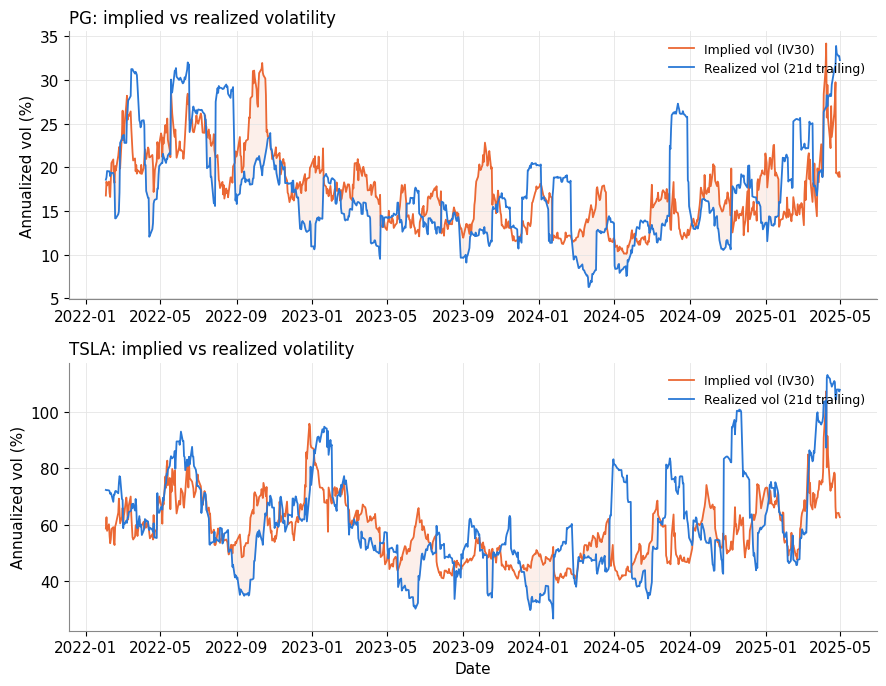

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(9, 7))
for ax, ticker in zip(axes, ["PG", "TSLA"]):
    df = data[ticker].loc[IV_SAMPLE_START:IV_SAMPLE_END]
    ax.plot(df.index, df["implied_vol"] * 100, label="Implied vol (IV30)", color=VOL_INPUT_COLOR["implied"], linewidth=1.3)
    ax.plot(df.index, df["realized_vol"] * 100, label="Realized vol (21d trailing)", color=VOL_INPUT_COLOR["realized"], linewidth=1.3)
    ax.fill_between(df.index, df["realized_vol"] * 100, df["implied_vol"] * 100,
                     where=(df["implied_vol"] >= df["realized_vol"]),
                     color=VOL_INPUT_COLOR["implied"], alpha=0.10, interpolate=True)
    ax.set_title(f"{ticker}: implied vs realized volatility", loc="left", fontsize=12)
    ax.set_ylabel("Annualized vol (%)")
    ax.legend(loc="upper right", frameon=False, fontsize=9)
axes[-1].set_xlabel("Date")
fig.tight_layout()
fig.savefig("fig1_vol_premium_timeseries.png", dpi=200)
plt.show()


### Fig 2 — Q1 result: hedge P&L distribution\nThe outcome plot: full distribution (not just the mean) of hedge P&L by which vol you hedged with.

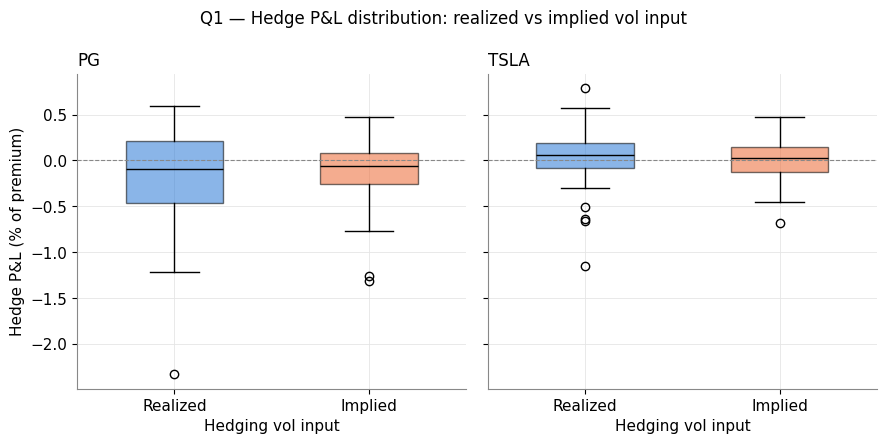

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5), sharey=True)
order = ["realized", "implied"]
for ax, ticker in zip(axes, ["PG", "TSLA"]):
    df = q1_results[ticker]
    box_data = [df.loc[df.vol_input == v, "hedge_pnl_pct_of_premium"].dropna() for v in order]
    bp = ax.boxplot(box_data, tick_labels=[v.capitalize() for v in order], patch_artist=True, widths=0.5, medianprops=dict(color="black"))
    for patch, v in zip(bp["boxes"], order):
        patch.set_facecolor(VOL_INPUT_COLOR[v])
        patch.set_alpha(0.55)
    ax.axhline(0, color="#888888", linewidth=0.8, linestyle="--")
    ax.set_title(ticker, loc="left", fontsize=12)
    ax.set_xlabel("Hedging vol input")
axes[0].set_ylabel("Hedge P&L (% of premium)")
fig.suptitle("Q1 — Hedge P&L distribution: realized vs implied vol input", fontsize=12)
fig.tight_layout()
fig.savefig("fig2_q1_hedge_pnl_boxplot.png", dpi=200)
plt.show()


## 7. Research Question 2 — Regime dependence

In [9]:
q2_rows, q2_detail = [], {}
for ticker, df in data.items():
    q = DIVIDEND_YIELD[ticker]
    for regime, (start, end) in REGIME_WINDOWS.items():
        window = df.loc[start:end]
        if window.empty:
            continue
        res = roll_hedging_strategy(window["price"], window["realized_vol"], r=RISK_FREE_RATE, q=q)
        res["ticker"], res["regime"] = ticker, regime
        q2_detail[(ticker, regime)] = res
        q2_rows.append({
            "ticker": ticker, "regime": regime, "n_cycles": len(res),
            "mean_pnl_pct": res["hedge_pnl_pct_of_premium"].mean(),
            "std_pnl_pct": res["hedge_pnl_pct_of_premium"].std(),
        })

q2_summary = pd.DataFrame(q2_rows)
print(q2_summary.to_string(index=False))
q2_all = pd.concat(q2_detail.values(), ignore_index=True)


ticker                regime  n_cycles  mean_pnl_pct  std_pnl_pct
    PG 2022_rate_hike_stress        10     -0.005159     0.316829
    PG             2023_calm        11     -0.209313     0.461265
    PG         2025_ai_shock         3     -0.351189     0.399062
  TSLA 2022_rate_hike_stress        10      0.013112     0.330627
  TSLA             2023_calm        11      0.057255     0.131498
  TSLA         2025_ai_shock         3      0.011176     0.394782


### Fig 3 — Q2 headline: mean hedge P&L by regime and ticker\nThe direct comparison: does TSLA move more than PG across regimes? (±1 standard error)

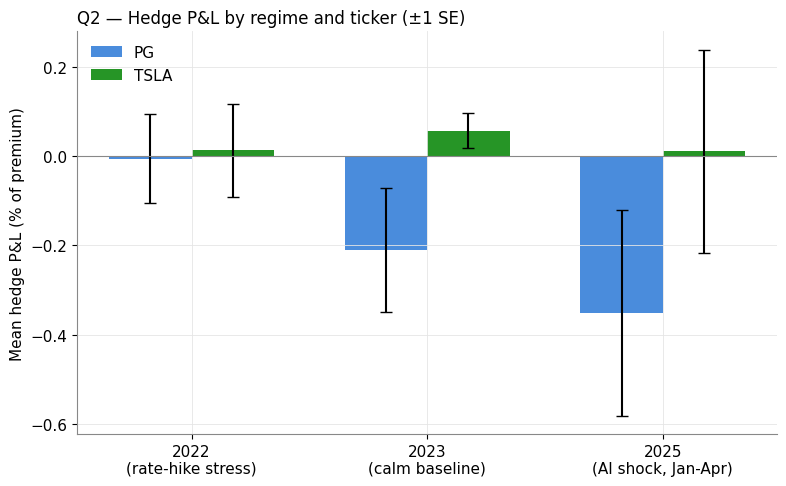

Note: 2025_ai_shock has only ~3 cycles per ticker (4-month window) -- treat as directional, not conclusive.


In [10]:
x = np.arange(len(REGIME_ORDER))
width = 0.35
fig, ax = plt.subplots(figsize=(8, 5))
for i, ticker in enumerate(["PG", "TSLA"]):
    sub = q2_summary[q2_summary.ticker == ticker].set_index("regime").reindex(REGIME_ORDER)
    se = sub["std_pnl_pct"] / np.sqrt(sub["n_cycles"])
    offset = (i - 0.5) * width
    ax.bar(x + offset, sub["mean_pnl_pct"], width, yerr=se, capsize=4, label=ticker, color=TICKER_COLOR[ticker], alpha=0.85)
ax.axhline(0, color="#888888", linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels([REGIME_LABEL[r] for r in REGIME_ORDER])
ax.set_ylabel("Mean hedge P&L (% of premium)")
ax.set_title("Q2 — Hedge P&L by regime and ticker (±1 SE)", loc="left", fontsize=12)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig("fig3_q2_regime_bars.png", dpi=200)
plt.show()
print("Note: 2025_ai_shock has only ~3 cycles per ticker (4-month window) -- treat as directional, not conclusive.")


### Fig 4 — Q2 supplementary: full distribution by regime\nReveals whether variance widens in stress regimes -- something the bar chart's error bars can only hint at.

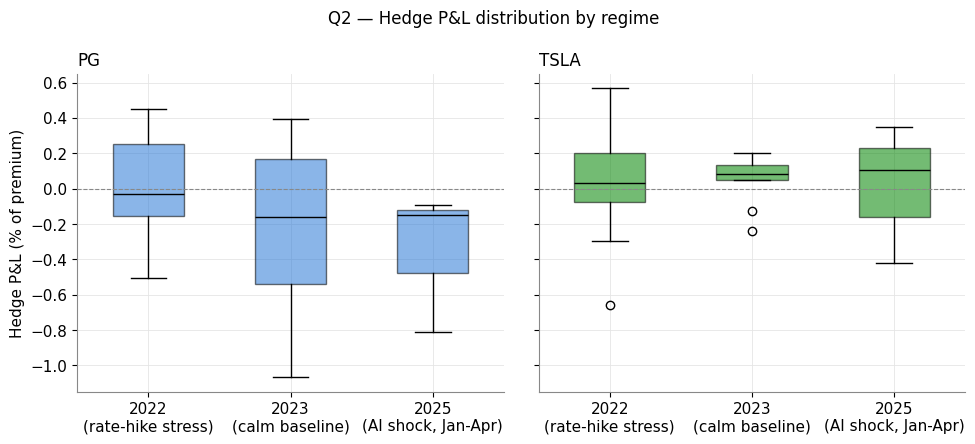

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)
for ax, ticker in zip(axes, ["PG", "TSLA"]):
    sub = q2_all[q2_all.ticker == ticker]
    box_data = [sub.loc[sub.regime == r, "hedge_pnl_pct_of_premium"].dropna() for r in REGIME_ORDER]
    bp = ax.boxplot(box_data, tick_labels=[REGIME_LABEL[r] for r in REGIME_ORDER], patch_artist=True, widths=0.5, medianprops=dict(color="black"))
    for patch in bp["boxes"]:
        patch.set_facecolor(TICKER_COLOR[ticker])
        patch.set_alpha(0.55)
    ax.axhline(0, color="#888888", linewidth=0.8, linestyle="--")
    ax.set_title(ticker, loc="left", fontsize=12)
axes[0].set_ylabel("Hedge P&L (% of premium)")
fig.suptitle("Q2 — Hedge P&L distribution by regime", fontsize=12)
fig.tight_layout()
fig.savefig("fig4_q2_regime_boxplot.png", dpi=200)
plt.show()


## Notes / limitations for the report

- **Q1 sample:** ~38 non-overlapping ~30-day cycles per stock over Jan 2022 - Apr 2025 — a reasonably
  solid, independent sample for the realized-vs-implied comparison.
- **Q2 2025 AI-shock window:** only ~3 cycles (Jan-Apr 2025 is a short window), so treat that regime's
  numbers as directional/illustrative rather than statistically conclusive.
- **Data source:** Bloomberg Terminal, HIVG function, Classical model, 30-day tenor, Ann. factor 252,
  price and implied vol pulled together on the same dates (Jan 3, 2022 - Apr 30, 2025).
- **Plot design:** each research question gets a "premise/mechanism" or "headline" plot plus a
  "distribution/robustness" plot, with consistent colors per ticker/vol-input across all four figures.
